In [1]:
# Patch for matplotlib_inline 0.2.2 incompatibility with newer matplotlib (see the hls4ml export notebook).
import matplotlib
if not hasattr(matplotlib.rcParams, "_get"):
    matplotlib.rcParams._get = matplotlib.rcParams.__getitem__

# Quantization-aware training with HGQ2 → hls4ml → Vitis HLS

This notebook goes from nothing to a synthesised FPGA design, with a **hexagonal CNN whose bit widths are learned**:

```
toy hex images ──► float CNN (reference)
       │
       └─► QAT CNN (QConv2d / QMaxPool2d, HGQ2 quantizers)
                │  trained with  loss + β · EBOPs   (the bit widths shrink where the task allows)
                ▼
          freeze()  ──►  plain hex layers holding the quantized values  +  an ap_fixed type per tensor
                ▼
          patch_model_for_hls()  +  apply_quantized_types()
                ▼
          hls4ml  ──►  C simulation (bit-exact check)  ──►  Vitis HLS synthesis (LUT / FF / DSP / latency)
```

Why bother: a hex convolution costs, per pixel, `7 taps × C_in × C_out` multiplications. Their cost on an FPGA
grows with the **bit widths** of the weights and activations, so letting the training find the narrowest
widths that still work is the cheapest way to shrink the design.

**What is quantized:** the hexagonal layers (weights, bias, input and output of each convolution). The small
dense head keeps hls4ml's default precision: it is not the point of this notebook.

**Requirements:** `pip install keras-hexagdly[qat] hls4ml` (HGQ2 needs Python ≥ 3.10) and, for the last
section, Vitis HLS (the C simulation only needs `g++`). Use the TensorFlow or torch Keras backend
(the hls4ml export is not available with JAX).

In [2]:
import os, shutil, stat, sys, tempfile

import numpy as np
import matplotlib.pyplot as plt
import keras

import hls4ml
from hgq.quantizer import QuantizerConfig
from hgq.utils.sugar import BetaScheduler, FreeEBOPs, PieceWiseSchedule

import keras_hexagdly as hgly
from keras_hexagdly.hls4ml_ext import apply_quantized_types, hex_reuse_config, patch_model_for_hls
from keras_hexagdly.hls4ml_handler import register_hex_gather_layers

# toy data shared with the other notebooks
sys.path.insert(0, os.getcwd())
from toy_data import ToyDataset

print("keras", keras.__version__, "| backend", keras.backend.backend())
keras.utils.set_random_seed(0)

2026-10-24 16:09:30.479705: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-24 16:09:30.479936: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-24 16:09:30.511329: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


keras 3.12.0 | backend tensorflow


## 1. Data and a float reference

Four hexagonal shapes on a 10×10 offset grid (the layout `keras-hexagdly` uses). A float CNN is trained
first: it is the accuracy to keep, and the design to beat in section 7.

In [3]:
shape_list = ["snowflake_2", "snowflake_3", "snowflake_4", "double_hex"]
H = W = 10
x_train, y_train = ToyDataset(shape_list, 128, H, W).create(seed=0).to_arrays()
x_val, y_val = ToyDataset(shape_list, 32, H, W).create(seed=1).to_arrays()
print("train", x_train.shape, " val", x_val.shape)


def float_cnn():
    inp = keras.Input((H, W, 1), name="image")
    x = hgly.Conv2d(8, kernel_size=2, share_neighbors=True, activation="relu", name="conv1")(inp)
    x = hgly.MaxPool2d(kernel_size=1, strides=2, name="pool1")(x)
    x = hgly.Conv2d(4, kernel_size=1, share_neighbors=True, activation="relu", name="conv2")(x)
    x = keras.layers.Flatten(name="flat")(x)
    x = keras.layers.Dense(16, activation="relu", name="fc1")(x)
    out = keras.layers.Dense(len(shape_list), name="logits")(x)
    return keras.Model(inp, out, name="float_hex_cnn")


def compile_model(m):
    m.compile(
        keras.optimizers.Adam(3e-3),
        keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"],
    )


float_model = float_cnn()
compile_model(float_model)
float_model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=150, batch_size=32, verbose=0)
float_acc = float_model.evaluate(x_val, y_val, verbose=0)[1]
print(f"float model: validation accuracy {float_acc:.3f}")

train (512, 10, 10, 1)  val (128, 10, 10, 1)


E0000 00:00:1792850974.077834 1899435 cuda_executor.cc:1309] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1792850974.087798 1899435 gpu_device.cc:2342] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


float model: validation accuracy 0.969


## 2. The QAT model

`QConv2d`, `QMaxPool2d`… are the hexagonal layers with [HGQ2](https://github.com/calad0i/HGQ2) quantizers
switched on one by one:

| argument | what it quantizes |
|---|---|
| `kq_conf` | the kernel (each sub-kernel of the hexagonal decomposition has its own quantizer) |
| `bq_conf` | the bias |
| `iq_conf` | the layer input |
| `oq_conf` | the layer output, **after** the activation |

Two choices here come from the hardware export:

* the **weights** get one learned bit width **per element** (`trainable=True`, the default): a weight that
  reaches 0 bit is pruned;
* the **activations** get one bit width **per layer** (`homogeneous_axis=(0, 1, 2, 3)`), because hls4ml's
  `io_stream` has one type per tensor.

The input images are 0/1 here, so the first input quantizer is unsigned (`signed=0`). The output quantizer
of a layer and the input quantizer of the next one describe the same tensor, so they are given the same
widths at the start.

In [4]:
def per_layer(ints, fracs, signed=1):
    """An activation quantizer with one learned bit width for the whole layer (sign + ints + fracs)."""
    return QuantizerConfig(
        "kif", "datalane", k0=signed, i0=ints, f0=fracs,
        overflow_mode="SAT", round_mode="RND", homogeneous_axis=(0, 1, 2, 3),
    )


# weights: sign + 1 integer bit + 7 fractional bits at the start, learned per element afterwards
weights = QuantizerConfig("kbi", "weight", k0=1, b0=8, i0=2)


def qat_cnn():
    inp = keras.Input((H, W, 1), name="image")
    x = hgly.QConv2d(
        8, kernel_size=2, share_neighbors=True, activation="relu", name="conv1",
        kq_conf=weights, bq_conf=weights, iq_conf=per_layer(1, 4, signed=0), oq_conf=per_layer(3, 4, signed=0),
    )(inp)
    x = hgly.QMaxPool2d(kernel_size=1, strides=2, name="pool1")(x)
    x = hgly.QConv2d(
        4, kernel_size=1, share_neighbors=True, activation="relu", name="conv2",
        kq_conf=weights, bq_conf=weights,
        iq_conf=per_layer(3, 4, signed=0), oq_conf=per_layer(3, 4, signed=0),
    )(x)
    x = keras.layers.Flatten(name="flat")(x)
    x = keras.layers.Dense(16, activation="relu", name="fc1")(x)
    out = keras.layers.Dense(len(shape_list), name="logits")(x)
    return keras.Model(inp, out, name="qat_hex_cnn")


qat_model = qat_cnn()
compile_model(qat_model)
qat_model.summary()

Model: "qat_hex_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 10, 10, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (QConv2d)                 │ (None, 10, 10, 8)      │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (QMaxPool2d)              │ (None, 5, 5, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (QConv2d)                 │ (None, 5, 5, 4)        │           280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flat (Flatten)                  │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 16)             │         1,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,100 (7.90 KB)

 Trainable params: 1,992 (7.78 KB)

 Non-trainable params: 108 (120.00 B)

## 3. Training with EBOPs

A convolution that has an input quantizer counts its cost in **EBOPs** (effective bit operations: the bits
of each weight times the bits of the input it multiplies, summed over the hexagon, zero padding excluded, a
pruned weight costing nothing). During training the loss becomes `loss + β · EBOPs`: the larger β, the harder
the bit widths are pushed down.

Rather than a fixed β, a **schedule** lets the network learn the task first, then squeezes it:
β = 0 for 40 epochs, then a linear ramp to its final value `3e-7`. HGQ2's `FreeEBOPs` callback records the EBOPs
of every epoch (they are the sum over the layers, here the two convolutions). `BetaPID` can instead aim at
a target EBOPs.

**Choosing β matters.** With the same network and data, `β = 3e-7` kept the accuracy on every seed tried,
while `β = 1e-6` and above sometimes pushed an input quantizer to 0 bit (the network then outputs a
constant: 25 % accuracy on four classes). Watch the validation accuracy next to the EBOPs, and lower β
if it falls.

QAT model: validation accuracy 0.992  (float: 0.969)
EBOPs: 744,224 at the start -> 195,955 at the end  (x3.8 fewer)


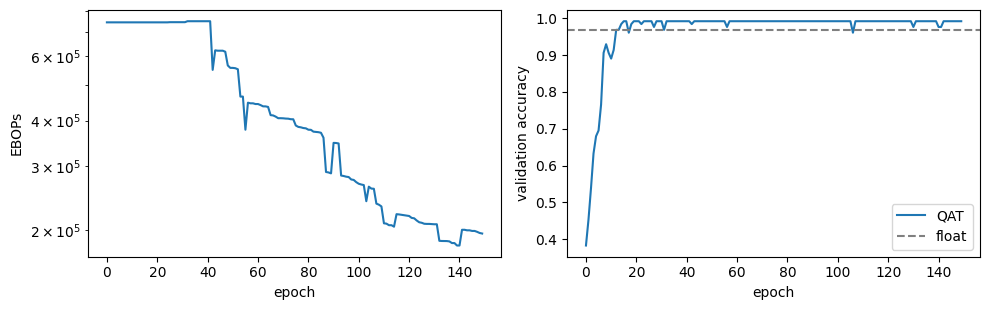

In [5]:
schedule = PieceWiseSchedule([(0, 0.0, "constant"), (40, 0.0, "linear"), (110, 3e-7, "constant")])
history = qat_model.fit(
    x_train, y_train, validation_data=(x_val, y_val), epochs=150, batch_size=32, verbose=0,
    callbacks=[FreeEBOPs(), BetaScheduler(schedule)],
)
qat_acc = qat_model.evaluate(x_val, y_val, verbose=0)[1]
ebops = history.history["ebops"]
print(f"QAT model: validation accuracy {qat_acc:.3f}  (float: {float_acc:.3f})")
print(f"EBOPs: {ebops[0]:,.0f} at the start -> {ebops[-1]:,.0f} at the end  (x{ebops[0] / ebops[-1]:.1f} fewer)")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(ebops); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("EBOPs"); ax[0].set_yscale("log")
ax[1].plot(history.history["val_accuracy"], label="QAT"); ax[1].axhline(float_acc, ls="--", c="gray", label="float")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

## 4. What the training learned

Each quantized layer can tell the exact `ap_fixed<W,I>` type of its tensors, read from the values themselves
(not from the quantizer parameters, which are only a bound):

In [6]:
for name in ("conv1", "conv2"):
    layer = qat_model.get_layer(name)
    kernels = np.concatenate([w.ravel() for w in layer.quantized_weights()])
    print(f"{name}:")
    print(f"  weights  {layer.weight_type():>12}   ({np.mean(kernels == 0):.0%} of the weights are exactly 0)")
    print(f"  bias     {layer.bias_type():>12}")
    print(f"  input    {layer.input_type()}")
    print(f"  output   {layer.result_type()}")
    print(f"  accumulator (exact) {layer.accum_type()}")

conv1:


  weights  ap_fixed<9,2>   (33% of the weights are exactly 0)
  bias     ap_fixed<6,0>
  input    ap_ufixed<2,1,AP_RND,AP_SAT>
  output   ap_ufixed<8,3,AP_RND,AP_SAT>
  accumulator (exact) ap_fixed<17,9>
conv2:
  weights  ap_fixed<9,2>   (34% of the weights are exactly 0)
  bias     ap_fixed<5,-1>
  input    ap_ufixed<5,3,AP_RND,AP_SAT>
  output   ap_ufixed<7,3,AP_RND,AP_SAT>
  accumulator (exact) ap_fixed<21,12>


## 5. Freeze: from the training model to the deployment model

`freeze()` returns a new model in which every quantized layer is back to its plain hexagonal layer **holding
the quantized values**, plus a `types` dict with the `ap_fixed` type of each tensor. It does not modify the
trained model.

With `activation_quantizers="keep"` the activation quantizers stay as standalone layers, so the frozen
model computes *exactly* what the QAT model computes: a check that nothing is lost.

In [7]:
checked, _ = hgly.freeze(qat_model, activation_quantizers="keep")
diff = float(np.max(np.abs(checked.predict(x_val, verbose=0) - qat_model.predict(x_val, verbose=0))))
print(f"max |frozen - QAT| on the validation set: {diff:.2e}")
assert diff < 1e-4

# for hls4ml the activation quantizers are replaced by types (io_stream has one type per tensor)
frozen, types = hgly.freeze(qat_model, activation_quantizers="types")
for name, entry in types.items():
    print(name, entry)

max |frozen - QAT| on the validation set: 0.00e+00
conv1 {'weight': 'ap_fixed<9,2>', 'bias': 'ap_fixed<6,0>', 'input': 'ap_ufixed<2,1,AP_RND,AP_SAT>', 'result': 'ap_ufixed<8,3,AP_RND,AP_SAT>', 'accum': 'ap_fixed<17,9>'}
pool1 {}
conv2 {'weight': 'ap_fixed<9,2>', 'bias': 'ap_fixed<5,-1>', 'input': 'ap_ufixed<5,3,AP_RND,AP_SAT>', 'result': 'ap_ufixed<7,3,AP_RND,AP_SAT>', 'accum': 'ap_fixed<21,12>'}


## 6. hls4ml: configuration, C simulation

`patch_model_for_hls` rewrites the hexagonal layers for the FPGA (line-buffer kernels, see the export notebook).
`apply_quantized_types` then puts every type of `types` where hls4ml expects it: weights and bias of the
MAC, the exact accumulator, the input type on the layer that feeds a convolution, the output type after its
activation. `hex_reuse_config` gives each hexagonal layer an explicit reuse factor.

In [8]:
register_hex_gather_layers("Vitis")
FPGA_PART = "xc7vx485tffg1927-2"   # XC7VX485T-2FFG1927C
CLOCK_NS = 5


def hls_config(patched, types=None):
    config = hls4ml.utils.config_from_keras_model(patched, granularity="name", backend="Vitis")
    # what is not quantized: the dense head. A confident classifier has large logits, and ap_fixed<16,6>
    # only reaches +-32, so the default is widened (the same for both designs below)
    config["Model"]["Precision"] = "ap_fixed<24,12>"
    config["Model"]["Strategy"] = "Resource"
    hex_reuse_config(config, patched, verbose=False)
    if types is not None:
        apply_quantized_types(config, patched, types)
    return config


def convert(patched, config, directory):
    if os.path.exists(directory):
        shutil.rmtree(directory)
    return hls4ml.converters.convert_from_keras_model(
        patched, hls_config=config, backend="Vitis", io_type="io_stream",
        output_dir=directory, part=FPGA_PART, clock_period=CLOCK_NS,
    )


patched_qat = patch_model_for_hls(frozen)
config_qat = hls_config(patched_qat, types)
for name in ("conv1_linebuffer", "conv1_activation"):
    print(name, config_qat["LayerName"][name])
hls_qat = convert(patched_qat, config_qat, os.path.join(tempfile.gettempdir(), "hls_qat_hex"))

conv1_linebuffer {'Trace': False, 'Precision': {'result': 'ap_fixed<17,9>', 'mac_weights': 'ap_fixed<9,2>', 'mac_bias': 'ap_fixed<6,0>'}, 'ReuseFactor': 1, 'Strategy': 'Resource', 'AccumPrecision': 'ap_fixed<17,9>'}
conv1_activation {'Trace': False, 'Precision': {'result': 'ap_ufixed<8,3,AP_RND,AP_SAT>', 'table': 'fixed<18,8,TRN,WRAP,0>'}, 'ReuseFactor': 1, 'TableSize': 1024}


In [9]:
hls_qat.compile()
x_csim = np.ascontiguousarray(x_val[:64])
y_hls = hls_qat.predict(x_csim)
y_keras = qat_model.predict(x_csim, verbose=0)
print(f"largest |logit| in Keras: {np.max(np.abs(y_keras)):.1f}")
print(f"C simulation vs the QAT Keras model: max |diff| of the logits = {np.max(np.abs(y_hls - y_keras)):.3f}")
print(f"same predicted class on {np.mean(np.argmax(y_hls, 1) == np.argmax(y_keras, 1)):.0%} of the samples")
print(f"C-simulation accuracy: {np.mean(np.argmax(y_hls, 1) == y_val[:64]):.3f}")

largest |logit| in Keras: 83.8
C simulation vs the QAT Keras model: max |diff| of the logits = 0.098
same predicted class on 100% of the samples
C-simulation accuracy: 1.000


The logits differ slightly because the **dense head** runs in `ap_fixed<24,12>` in hardware and in float in
Keras (with `ap_fixed<16,6>` the largest logits, above 32, would wrap around: check the range of your own
logits before choosing a precision). The convolutions themselves are bit-exact: with the exact accumulator (`AccumPrecision`), the output of
the quantized convolutions in the C simulation equals the Keras output, which `tests/test_quantized_csim.py`
checks on every release.

## 7. Vitis HLS synthesis, against a uniform-precision design

The fair comparison is the same float network exported the usual way: every weight and activation in
`ap_fixed<24,12>`. Both designs use the same part, clock, strategy and per-layer reuse factors.
The uniform precision is `ap_fixed<24,12>`, wide enough for the largest logits (above 32 in this run, which `ap_fixed<16,6>` would wrap around):
a hand-tuned uniform precision, narrower per layer, would land between the two designs.

Synthesis takes a minute or so per design here and needs Vitis HLS (`hls4ml` still looks for `vivado_hls`: a one-line
shim to `vitis_hls` is created once).

In [10]:
VITIS_BIN = "/tools/Xilinx/Vitis_HLS/2024.2/bin"
os.environ["PATH"] = VITIS_BIN + ":" + os.environ.get("PATH", "")
shim = os.path.expanduser("~/.local/bin/vivado_hls")
if not os.path.isfile(shim):
    os.makedirs(os.path.dirname(shim), exist_ok=True)
    with open(shim, "w") as f:
        f.write(f"#!/bin/bash\nexec {VITIS_BIN}/vitis_hls \"$@\"\n")
    os.chmod(shim, os.stat(shim).st_mode | stat.S_IEXEC | stat.S_IXGRP | stat.S_IXOTH)

patched_float = patch_model_for_hls(float_model)
hls_float = convert(patched_float, hls_config(patched_float), os.path.join(tempfile.gettempdir(), "hls_float_hex"))

for label, model in (("float, uniform <24,12>", hls_float), ("QAT, learned bit widths", hls_qat)):
    print("synthesising:", label)
    model.build(csim=False, synth=True, export=False)

synthesising: float, uniform <24,12>
[1 lines of the Vitis HLS log trimmed]


[8 lines of the Vitis HLS log trimmed]


[24 lines of the Vitis HLS log trimmed]


[11 lines of the Vitis HLS log trimmed]


[6 lines of the Vitis HLS log trimmed]


...

[27 lines of the Vitis HLS log trimmed]


[31 lines of the Vitis HLS log trimmed]


[1 lines of the Vitis HLS log trimmed]


INFO: [HLS 200-789] **** Estimated Fmax: 217.53 MHz
***** C/RTL SYNTHESIS COMPLETED IN 0h0m37s *****
[8 lines of the Vitis HLS log trimmed]


[5 lines of the Vitis HLS log trimmed]


In [11]:
def resources(model):
    """The csynth estimates of a synthesised model."""
    return hls4ml.report.parse_vivado_report(model.config.get_output_dir())["CSynthesisReport"]


rows = {"float, uniform <24,12>": resources(hls_float), "QAT, learned bit widths": resources(hls_qat)}
print(f"{'design':<26}{'LUT':>10}{'FF':>10}{'DSP':>8}{'BRAM_18K':>10}{'latency':>10}")
for label, r in rows.items():
    print(f"{label:<26}{r['LUT']:>10}{r['FF']:>10}{r['DSP']:>8}{r['BRAM_18K']:>10}{r['WorstLatency']:>10}")
print(f"\nvalidation accuracy: float {float_acc:.3f}, QAT {qat_acc:.3f}")

Vivado synthesis report not found.
Cosim report not found.
Timing report not found.
Vivado synthesis report not found.
Cosim report not found.
Timing report not found.
design                           LUT        FF     DSP  BRAM_18K   latency
float, uniform <24,12>         60266    189012    1642        45       171
QAT, learned bit widths        43847     67404    1355        17       167

validation accuracy: float 0.969, QAT 0.992


These are Vitis HLS **estimates** after C synthesis (not place and route), for one small network, so read them as
an illustration, not as a benchmark. Narrower multiplications move from DSP blocks to LUTs, so compare the
whole picture (LUT, FF and DSP together) rather than one column. Vitis prints a few messages about an
`array_partition` option while it runs (a known mismatch between hls4ml's Vitis backend and Vitis 2024.2); the
synthesis completes and the reports above come from it.

## Going further

* **The accumulator.** `apply_quantized_types` gives each convolution its exact accumulator
  (`accumulator="exact"`, the default). `accumulator="default"` leaves hls4ml's own accumulator, which is
  narrower and cheaper but drops the low bits of each product (`config["Model"]["ExactAccumulator"] = True`
  switches the exact one on for the whole model instead).
* **Aim at a target.** Replace the schedule by `BetaPID(target_ebops=...)` to let HGQ2 tune β.
* **WRAP quantizers.** With `overflow_mode="WRAP"` call `hgq.utils.trace_minmax(model, data)` after training to
  find the integer bits the data needs.
* **Co-simulation.** Add `input_data_tb` / `output_data_tb` to `convert_from_keras_model` and call
  `model.build(cosim=True, validation=True)`, as in the hls4ml export notebook.
* **Your own model.** Only the hexagonal layers (`QConv2d`, `QMaxPool2d`) are quantized here; a dense head
  can use HGQ2's own `QDense` for an end-to-end quantized network, but that goes through HGQ2's hls4ml
  plugin and is outside the scope of this notebook.